In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

The analysis will focus on understanding the frequency, types and timing of race-control events across the 2021–2025 seasons.

In [3]:
df = pd.read_parquet("../Data/processed/all_race_control_cleaned.parquet")

print("Dataset shape:", df.shape)

Dataset shape: (10187, 17)


We will explore the frequency of each race-control event category to find how the distribution of the events.

In [5]:
# Event category counts
category_counts = df["Category"].value_counts()

category_counts

Category
Flag         5420
Other        4027
Drs           320
SafetyCar     280
CarEvent      140
Name: count, dtype: int64

In [6]:
# Event category percentages.
display((df["Category"].value_counts(normalize=True) * 100).round(2))

Category
Flag         53.21
Other        39.53
Drs           3.14
SafetyCar     2.75
CarEvent      1.37
Name: proportion, dtype: float64

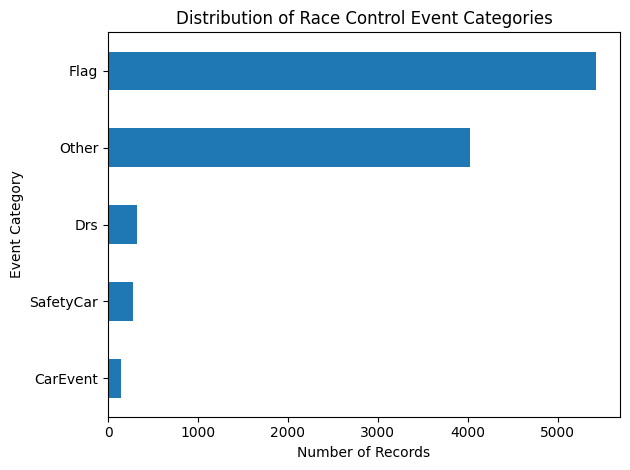

In [11]:
category_counts.sort_values().plot(kind="barh")

plt.title("Distribution of Race Control Event Categories")
plt.xlabel("Number of Records")
plt.ylabel("Event Category")
plt.tight_layout()
plt.show()

The distribution of race-control records is heavily concentrated in the Flag and Other categories, accounting for 53.21% and 39.53% of all records respectively. These categories represent approximately 92.74% of the dataset.

SafetyCar, DRS and CarEvent records make up a smaller proportion. We will need to distinguishing routine race-control communications from significant events that can influence race strategy.



Safety Car (SC) and Virtual Safety Car (VSC) periods can influence pit-stop strategy by changing the time cost and competitive consequences of stopping.

We will explore the frequency of SC and VSC deployment announcements across the 2021–2025 seasons.

In [12]:
safety_deployments = df[df["Message"].isin(["SAFETY CAR DEPLOYED", "VIRTUAL SAFETY CAR DEPLOYED"])].copy()

safety_deployments["SafetyCarType"] = safety_deployments["Message"].map({
    "SAFETY CAR DEPLOYED": "Safety Car",
    "VIRTUAL SAFETY CAR DEPLOYED": "Virtual Safety Car"
})

deployment_counts = pd.crosstab(safety_deployments["year"], safety_deployments["SafetyCarType"])

# SC and VSC deployments by year
deployment_counts

SafetyCarType,Safety Car,Virtual Safety Car
year,,
2021,15,12
2022,20,23
2023,16,10
2024,13,9
2025,17,13


In [13]:
# Total Deployments
deployment_counts.sum()

SafetyCarType
Safety Car            81
Virtual Safety Car    67
dtype: int64

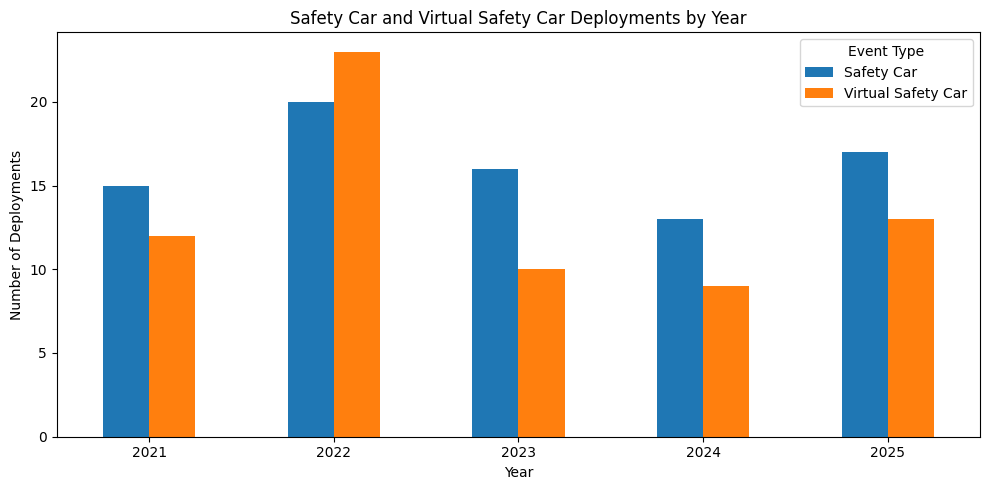

In [14]:
deployment_counts.plot(kind="bar", figsize=(10, 5))

plt.title("Safety Car and Virtual Safety Car Deployments by Year")
plt.xlabel("Year")
plt.ylabel("Number of Deployments")
plt.xticks(rotation=0)
plt.legend(title="Event Type")
plt.tight_layout()
plt.show()

2022 had the highest number of deployments.
- 20 Safety Car deployments.
- 23 Virtual Safety Car deployments.
- 43 combined deployments.

2024 had the lowest number.
- 13 Safety Car deployments.
- 9 Virtual Safety Car deployments.
- 22 combined deployments.

There were 14 more physical Safety Car deployments than VSC deployments across the five seasons.

VSC deployments exceeded physical Safety Car deployments in 2022, whereas physical Safety Cars were more frequent in every other year.

Since these are raw counts(not deployments per race) and the number of races can vary per season, we cannot conclude that there is a greater likelihood of sc being deployed.

We will investigate how frequently safety car periods occur during races.

In [15]:
sc_by_event = safety_deployments.groupby(["year", "event", "SafetyCarType"]).size().unstack(fill_value=0)

sc_by_event["Total"] = (sc_by_event["Safety Car"] + sc_by_event["Virtual Safety Car"])

# Top 15 races by total SC/VSC deployments
sc_by_event.sort_values("Total", ascending=False).head(15)

SafetyCarType                  Safety Car  Virtual Safety Car  Total
year event                                                          
2021 Saudi Arabian Grand Prix           1                   4      5
2022 Singapore Grand Prix               2                   3      5
2024 Qatar Grand Prix                   3                   1      4
2023 Australian Grand Prix              3                   1      4
2022 Australian Grand Prix              2                   2      4
2025 British Grand Prix                 2                   2      4
     Dutch Grand Prix                   3                   1      4
2022 Saudi Arabian Grand Prix           1                   2      3
     Canadian Grand Prix                1                   2      3
2021 Italian Grand Prix                 1                   2      3
     São Paulo Grand Prix               1                   2      3
2025 Miami Grand Prix                   0                   3      3
     Australian Grand Prix              3                   0      3
2024 São Paulo Grand Prix               2                   1      3
2022 French Grand Prix                  1                   2      3

The highest number of deployments in a single race was five, recorded at:
- 2021 Saudi Arabian Grand Prix: 1 Safety Car and 4 VSC deployments.
- 2022 Singapore Grand Prix: 2 Safety Cars and 3 VSC deployments.

The 2021 Saudi Arabian Grand Prix stands out because of its high number of VSC deployments.

The 2022 Singapore Grand Prix had a kind of balanced distribution between Safety Cars and VSCs.

Some races experienced only one type of the 2. Eg. the 2025 Miami Grand Prix had three VSC deployments and no full Safety Car deployments.

*The deployment of safety cars or virtual safety cars are known as neutralization events.*

Since neutralisation events are not evenly distributed across races some races experience several opportunities for advantageous pit stops, while others may have none.

We will try to figure out how many races experienced at least one Safety Car or VSC deployment, compared with the total number of races

In [22]:
# Count deployments in each race
race_deployment_counts = safety_deployments.groupby(["year", "round", "event"]).size().rename("Deployments")

# Get every race in the dataset
all_races = df[["year", "round", "event"]].drop_duplicates()

# Include races with zero deployments
race_deployment_counts = all_races.merge(race_deployment_counts, on=["year", "round", "event"], how="left")

race_deployment_counts["Deployments"] = race_deployment_counts["Deployments"].fillna(0).astype(int)

total_races = len(race_deployment_counts)

races_with_deployments = (race_deployment_counts["Deployments"] > 0).sum()

print("Total races:", total_races)
print("Races with at least one deployment:", races_with_deployments)

print(
    "Percentage of races with deployments:",
    round(races_with_deployments / total_races * 100, 2),
    "%"
)

Total races: 114
Races with at least one deployment: 78
Percentage of races with deployments: 68.42 %


In [ ]:
# Distribution of deployments per race.
(
    race_deployment_counts["Deployments"]
    .value_counts()
    .sort_index()
    .rename_axis("Number of Deployments")
    .to_frame("Number of Races")
)

,Number of Races
Number of Deployments,
0,36
1,35
2,25
3,11
4,5
5,2


Out of 114 races in the dataset:
- 78 races (68.42%) had at least one recorded deployment.
- 36 races (31.58%) had no recorded deployment.
- The dataset contains 148 deployment announcements in total.

Most races had either zero, one or two deployments.

18 races had three or more deployments.

Only seven races had four or five deployments.

In races with at least one deployment, the average was approximately 1.9 deployments per race.

Safety Car and VSC are common enough to be an important component of our strategy model. 
However, their occurrence is uncertain, and their distribution varies considerably between races.